# Grid-cell satellite features

Build the satellite features (tropospheric NO2 and the absorbing aerosol index, monthly means) for every cell of the analysis grid (Phase K). Notebook 03 only produced them at the station points. The definitive model from notebook 09, a Ridge regression, needs the same features in every cell to predict PM2.5 where there is no station (Phase L). The grid has about 435,000 cells, far too many for the interactive `reduceRegions` call used for the stations, so the monthly composites are exported as rasters and aggregated onto the grid locally.

In [1]:
%load_ext autoreload
%autoreload 2

## Imports

In [2]:
from pathlib import Path

import dotenv
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import xarray as xr
import rioxarray
import yaml
from tqdm.auto import tqdm

import ee
import geemap

import monitoring_deserts.data.fetch_earthengine as fetch_ee
import monitoring_deserts.data.fetch_population as fetch_pop


## Configuration

Read the configuration parameters from the previous steps and the general project config. Initialize the Earth Engine client.

In [3]:
# Generic settings
with open("../configs/project_config.yaml") as f:
    gen_config = yaml.safe_load(f)

RAW_DATA_DIR = Path(gen_config["data_dir"]["raw"]) / "satellite" / "grid" # exported rasters, one per month and band
CLEAN_DATA_DIR = Path(gen_config["data_dir"]["clean"]) / "satellite"
PROCESSED_DATA_DIR = Path(gen_config["data_dir"]["processed"]) # The data/processed/ should have no subdirs
MAPS_DIR = Path(gen_config["output_dir"]["maps"]) / "grid_satellite"
PLOTS_DIR = Path(gen_config["output_dir"]["plots"]) / "grid_satellite"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)
MAPS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Spacetime settings
with open("../configs/census_scope.yaml") as f:
    census_config = yaml.safe_load(f)

BOUNDING_BOX = tuple(census_config["bounding_box"].values())
DAY_START, DAY_END = census_config["period"]["start"], census_config["period"]["end"]

# Satellite settings of notebook 03: same collections, bands and scale, so station and grid features match
with open("../configs/satellite_metadata.yaml") as f:
    sat_config = yaml.safe_load(f)

REDUCER_SCALE = sat_config["reducer_scale_m"]
IMAGE_COLLECTIONS = {name: spec.split(":") for name, spec in sat_config["image_collections"].items()} # name -> [collection id, band]

# The analysis grid from notebook 04 (cell_id, centroid_lon, centroid_lat, geometry)
analysis_grid = gpd.read_parquet(PROCESSED_DATA_DIR / "grid.parquet")

# Monthly windows, built exactly as in notebook 03
m_win = fetch_ee.build_month_windows(DAY_START, DAY_END)

# Initialize client
dotenv.load_dotenv()
ee.Initialize(project="monitoring-deserts")

## Outline

1. ~~**Step 1 - Build the monthly composite images.** Reuse the collections, bands and monthly windows of notebook 03 (`fetch_ee.build_month_windows`) and take the mean of each band over each month, so a station and a grid cell are measured the same way. A mean composite loses the native projection of the source images, so it is put back with `setDefaultProjection`.~~
2. ~~**Step 2 - Download one month and check it.** The plan exports each composite with `Export.image.toDrive` and aggregates it locally with `rasterstats`. The repository's `fetch_ee.download_image_on_grid` instead downloads small tiles already reduced onto the grid (mean and standard deviation of the source pixels in every cell), with no Drive step and no new dependency. Try it on one month and compare the shape, the share of missing cells and the range of the values with the station values from notebook 03.~~
3. ~~**Step 3 - Download all months.** Run it for the 16 months and 2 variables. Cache each result in `RAW_DATA_DIR` as soon as it is done, as notebook 03 does with its temporary files, so an interrupted run can be resumed.~~
4. ~~**Step 4 - Put the values in a table keyed on the grid.** Read every cached array at each cell by `cell_id` and name the columns as in the station table (`cell_id`, `month`, `no2`, `no2_sd`, `aai`, `aai_sd`) so the model's feature names line up.~~
5. ~~**Step 5 - Check the result.** Look at the share of missing values per month (July 2025 was the worst month for NO2 at the stations), compare the distribution of the grid features with that of the stations (the model will be applied in places that may differ from where the stations sit), and compare each station's value with the value of the cell that contains it.~~
6. ~~**Step 6 - Assemble the grid feature table for Phase L.** Join the satellite features with the gridded ERA5 meteorology from notebook 05 and the population layers from notebook 06, add `sin_month` and `cos_month`, and check that the features of the definitive model recorded under `definitive_model` in `configs/model_training_metadata.yaml` are all there.~~
7. ~~**Step 7 - Save.** Write the satellite features to `data/clean/satellite/`, the assembled table to `data/processed/` and the metadata to `configs/grid_satellite_metadata.yaml`. Phase L (notebook 11) loads the fitted Ridge from `data/models/ridge_best.joblib` and predicts on the assembled table.~~

## Step 1 - Monthly composite images

Same collections, bands and windows as notebook 03, so a station and a grid cell are measured the same way: the mean of all the images of the month. `collection.mean()` loses the native projection of the source images, and the resampling onto the grid needs one, so it is put back with `setDefaultProjection` from the first image of the collection.

In [4]:
collections = {name: ee.ImageCollection(collection_id).select(band) for name, (collection_id, band) in IMAGE_COLLECTIONS.items()}
native_projection = {name: collection.first().projection() for name, collection in collections.items()}


def month_composite(name, month_start, month_end):
    """Mean image of one variable over one window, with the source images' projection restored."""
    window = collections[name].filterDate(month_start, month_end)
    if window.size().getInfo() == 0:
        raise RuntimeError(f"No {name} images between {month_start} and {month_end}.")
    return window.mean().setDefaultProjection(native_projection[name])


# One cheap server-side check that every month has images, before any download starts
n_images = pd.DataFrame(
    {name: [collection.filterDate(start, end).size().getInfo() for start, end in m_win] for name, collection in collections.items()},
    index=[start.strftime("%Y-%m") for start, _ in m_win],
)
n_images

,no2,aai
2025-03,439,439
2025-04,426,426
2025-05,438,439
2025-06,426,426
2025-07,440,440
2025-08,439,440
2025-09,422,424
2025-10,338,439
2025-11,386,424
2025-12,440,436


Every month needs images for both variables. A month with zero images would stop the download with an error naming the month.

## Step 2 - Download one month and check it

`fetch_ee.download_image_on_grid` reduces the source pixels inside every 0.05 degree cell (mean and standard deviation) and downloads the result in tiles. Each tile is a small request, so the interactive limits that rule out `reduceRegions` for 435,000 cells do not apply, and there is no Drive export to wait for.

The grid's raster axes are built as in notebook 06: the centroids are rounded because shapely computes them with floating-point noise, and rasters are north-up, so the row index descends with latitude.

In [5]:
CELL_SIZE = gen_config["grid_cell_size_deg"]

grid_lons = np.sort(analysis_grid["centroid_lon"].round(9).unique())
grid_lats = np.sort(analysis_grid["centroid_lat"].round(9).unique())
assert len(grid_lons) * len(grid_lats) == len(analysis_grid), "analysis_grid is not a full regular grid"

# Raster position of every cell, so values are read back by cell_id and not by row order
col = np.searchsorted(grid_lons, analysis_grid["centroid_lon"].round(9).values)
row = len(grid_lats) - 1 - np.searchsorted(grid_lats, analysis_grid["centroid_lat"].round(9).values)

MEAN_AND_SD = ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True)


def download_month(name, month_start, month_end):
    """Grid-reduced mean and standard deviation of one variable and month, shape (2, rows, cols)."""
    band = IMAGE_COLLECTIONS[name][1]
    return fetch_ee.download_image_on_grid(
        month_composite(name, month_start, month_end),
        grid_lons, grid_lats, CELL_SIZE,
        reducer=MEAN_AND_SD,
        bands=[f"{band}_mean", f"{band}_stdDev"],
        tile_cells=100,
        progress=True,
        max_workers=6,
        retries=5,
    )


print(f"Grid: {len(grid_lats)} rows x {len(grid_lons)} columns")

Grid: 659 rows x 660 columns


In [6]:
test_start, test_end = m_win[0]
test_grid = {name: download_month(name, test_start, test_end) for name in IMAGE_COLLECTIONS}

station_test = pd.read_parquet(CLEAN_DATA_DIR / "satellite_df.parquet")
station_test = station_test[station_test["month"] == test_start.to_period("M")]

quantiles = [0.05, 0.5, 0.95]
test_summary = pd.DataFrame({
    name: {
        "array_shape": test_grid[name].shape,
        "share_nan_mean_band": np.isnan(test_grid[name][0]).mean(),
        **{f"grid_q{int(q * 100):02d}": np.nanquantile(test_grid[name][0], q) for q in quantiles},
        **{f"station_q{int(q * 100):02d}": station_test[name].quantile(q) for q in quantiles},
    }
    for name in IMAGE_COLLECTIONS
}).T
print(f"Month {test_start:%Y-%m}")
test_summary

Grid tiles:   0%|          | 0/16 [00:00<?, ?it/s]

Grid tiles:   0%|          | 0/16 [00:00<?, ?it/s]

Month 2025-03


,array_shape,share_nan_mean_band,grid_q05,grid_q50,grid_q95,station_q05,station_q50,station_q95
no2,"(2, 659, 660)",0.0,0.000005,0.000013,0.000049,0.000028,0.00006,0.000138
aai,"(2, 659, 660)",0.0,-0.600083,-0.192603,0.595023,-0.341144,0.136404,0.430948


Reading the table: the shape must be `(2, rows, cols)` with the grid's rows and columns; the grid and station quantiles are not expected to match exactly (a station value is the mean of the pixels within 2 km, a cell value the mean over about 5 km), but they should be of the same order and sign convention. A large share of NaN cells, or values orders of magnitude away from the stations', means the projection trick did not work and the plan's `Export.image.toDrive` route is the fallback.

## Step 3 - Download all months

One file per variable and month in `RAW_DATA_DIR`, written as soon as the download finishes. A rerun skips the files that exist, so an interrupted run resumes where it stopped.

In [6]:
def grid_path(name, month_start):
    return RAW_DATA_DIR / f"grid_{name}_{month_start:%Y-%m}.npy"


for month_start, month_end in tqdm(m_win, desc="Months"):
    for name in IMAGE_COLLECTIONS:
        path = grid_path(name, month_start)
        if path.exists():
            continue
        np.save(path, download_month(name, month_start, month_end).astype("float32"))

missing_files = [grid_path(name, start).name for start, _ in m_win for name in IMAGE_COLLECTIONS if not grid_path(name, start).exists()]
assert not missing_files, f"Missing files: {missing_files}"
print(f"{len(m_win) * len(IMAGE_COLLECTIONS)} files in {RAW_DATA_DIR}")

Months:   0%|          | 0/16 [00:00<?, ?it/s]

32 files in ../data/raw/satellite/grid


## Step 4 - Table keyed on the grid

Each array is read at every cell's raster position, so the rows follow `cell_id` and not the raster order. The columns and the monthly period type match the station table of notebook 03 (`satellite_df`).

In [7]:
month_frames = []
for month_start, _ in m_win:
    frame = {"cell_id": analysis_grid["cell_id"].values, "month": month_start.to_period("M")}
    for name in IMAGE_COLLECTIONS:
        values = np.load(grid_path(name, month_start))
        frame[name] = values[0][row, col]
        frame[f"{name}_sd"] = values[1][row, col]
    month_frames.append(pd.DataFrame(frame))

grid_satellite_df = pd.concat(month_frames, ignore_index=True)
del month_frames
print(f"{len(grid_satellite_df):,} rows = {grid_satellite_df['cell_id'].nunique():,} cells x {grid_satellite_df['month'].nunique()} months")
grid_satellite_df.head()

6,959,040 rows = 434,940 cells x 16 months


,cell_id,month,no2,no2_sd,aai,aai_sd
0,0,2025-03,0.000004,7.880610e-07,-0.413141,0.019982
1,1,2025-03,0.000004,8.887752e-07,-0.429989,0.014610
2,2,2025-03,0.000003,7.603656e-07,-0.415326,0.020622
3,3,2025-03,0.000004,1.204352e-06,-0.355430,0.038641
4,4,2025-03,0.000006,1.051200e-06,-0.316459,0.029621


## Step 5 - Checks

Three questions. How much is missing, and where? Do the grid values look like the station values the model was trained on? Does a station's value agree with the value of the cell that contains it?

,no2,aai
month,,
2025-03,0.00%,0.00%
2025-04,0.00%,0.00%
2025-05,0.00%,0.00%
2025-06,0.00%,0.00%
2025-07,0.00%,0.00%
2025-08,0.00%,0.00%
2025-09,0.00%,0.00%
2025-10,0.00%,0.00%
2025-11,0.00%,0.00%


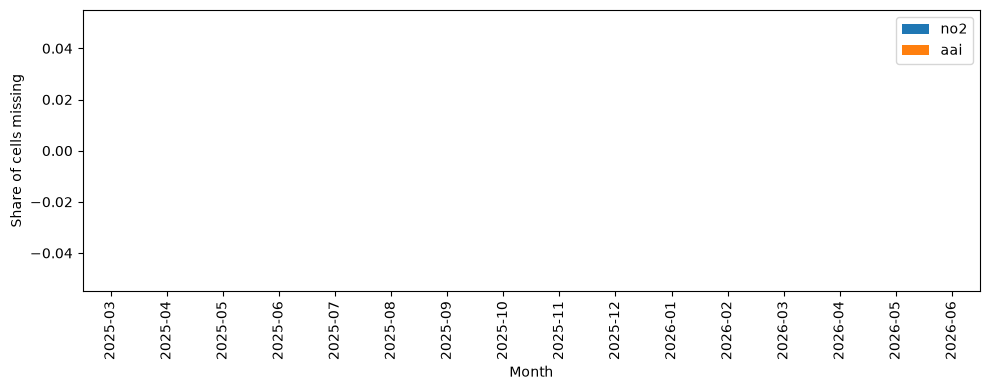

In [8]:
# Share of cells without a value, per month
nan_by_month = grid_satellite_df[["no2", "aai"]].isna().groupby(grid_satellite_df["month"]).mean()
display(nan_by_month.style.format("{:.2%}"))

fig, ax = plt.subplots(figsize=(10, 4))
nan_by_month.plot.bar(ax=ax)
ax.set_ylabel("Share of cells missing")
ax.set_xlabel("Month")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "nan_share_by_month.png", dpi=150)
plt.show()

no2                 aai          
          grid  stations      grid  stations
0.05  0.000005  0.000020 -0.768012 -0.793993
0.25  0.000008  0.000034 -0.469107 -0.480317
0.50  0.000012  0.000050 -0.217487 -0.022188
0.75  0.000021  0.000078  0.185361  0.272000
0.95  0.000043  0.000146  1.070309  0.768145

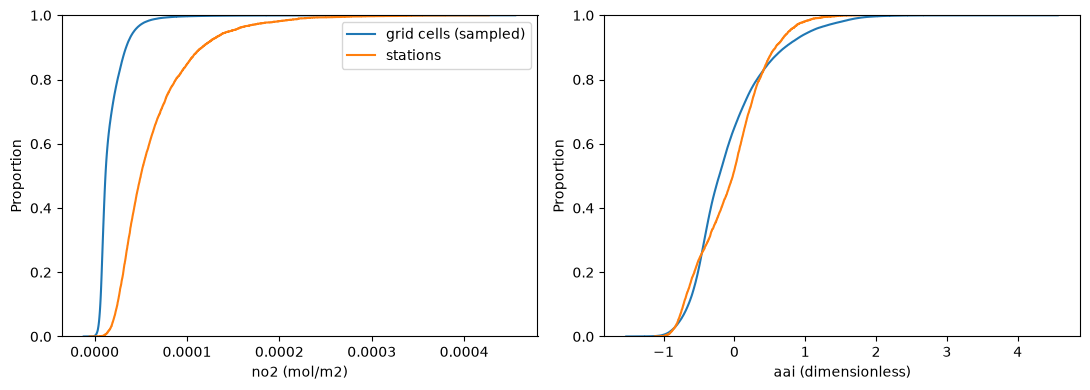

In [9]:
# Grid vs station distributions: the model is applied to cells that may differ from the station sites
stations = pd.read_parquet(CLEAN_DATA_DIR / "analysis_df.parquet")[["station_id", "month", "longitude", "latitude", "no2", "aai"]]

RANDOM_STATE = 42
levels = [0.05, 0.25, 0.5, 0.75, 0.95]
distribution_table = pd.concat(
    {name: pd.DataFrame({"grid": grid_satellite_df[name].quantile(levels), "stations": stations[name].quantile(levels)}) for name in IMAGE_COLLECTIONS},
    axis=1,
)
display(distribution_table)

fig, axes = plt.subplots(1, len(IMAGE_COLLECTIONS), figsize=(11, 4))
for ax, name in zip(axes, IMAGE_COLLECTIONS):
    grid_values = grid_satellite_df[name].dropna()
    sns.ecdfplot(grid_values.sample(min(200_000, len(grid_values)), random_state=RANDOM_STATE), ax=ax, label="grid cells (sampled)")
    sns.ecdfplot(stations[name].dropna(), ax=ax, label="stations")
    ax.set_xlabel(f"{name} ({sat_config['units'][name]})")
axes[0].legend()
fig.tight_layout()
fig.savefig(PLOTS_DIR / "grid_vs_station_distribution.png", dpi=150)
plt.show()

In [10]:
# Share of grid cell-months whose value lies outside what the training stations cover.
# The Ridge extrapolates linearly there, so these are the predictions to trust least.
coverage = {}
for name in IMAGE_COLLECTIONS:
    station_values = stations[name].dropna()
    grid_values = grid_satellite_df[name].dropna()
    low_1, high_99 = station_values.quantile([0.01, 0.99])
    coverage[name] = {
        "station_min": station_values.min(),
        "station_max": station_values.max(),
        "below_station_min": (grid_values < station_values.min()).mean(),
        "above_station_max": (grid_values > station_values.max()).mean(),
        "below_station_p01": (grid_values < low_1).mean(),
        "above_station_p99": (grid_values > high_99).mean(),
    }
display(pd.DataFrame(coverage).T.style.format({
    "station_min": "{:.3g}", "station_max": "{:.3g}",
    "below_station_min": "{:.2%}", "above_station_max": "{:.2%}",
    "below_station_p01": "{:.2%}", "above_station_p99": "{:.2%}",
}))

,station_min,station_max,below_station_min,above_station_max,below_station_p01,above_station_p99
no2,-5.75e-06,0.000427,0.00%,0.00%,56.61%,0.03%
aai,-1.13,1.77,0.12%,0.76%,1.50%,4.51%


Reading notes: the first two share columns count cells beyond the extreme station values (no training example there at all); the last two use the stations' 1st and 99th percentiles, a less outlier-driven version. A large share below the stations' range means the model will often be predicting in cleaner air than any station measured, where a linear model can return implausibly low or negative values. This is a limitation for Phase L and Phase O, and the shares are the numbers to quote. The meteorological features (Step 6) can be checked the same way.

5,504 station-months matched to a cell value


,pairs_with_both_values,spearman,median_station,median_cell
no2,5492.0,0.994372,0.000050,0.000049
aai,5504.0,0.998249,-0.022188,-0.036304


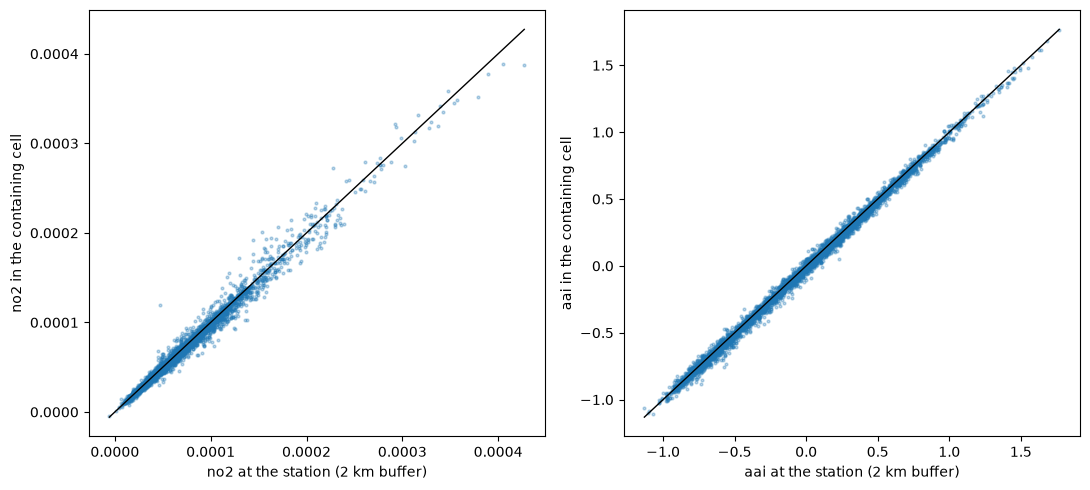

In [11]:
# Each station against the cell that contains it, month by month
st_col, st_lat_idx = fetch_pop.locate_grid_cells(stations["longitude"], stations["latitude"], grid_lons, grid_lats, CELL_SIZE)
cell_id_raster = np.empty((len(grid_lats), len(grid_lons)), dtype=analysis_grid["cell_id"].dtype)
cell_id_raster[row, col] = analysis_grid["cell_id"].values
stations["cell_id"] = cell_id_raster[len(grid_lats) - 1 - st_lat_idx, st_col]

station_vs_cell = stations.merge(grid_satellite_df[["cell_id", "month", "no2", "aai"]], on=["cell_id", "month"], suffixes=("_station", "_cell"))
print(f"{len(station_vs_cell):,} station-months matched to a cell value")

agreement = pd.DataFrame({
    name: {
        "pairs_with_both_values": int(station_vs_cell[[f"{name}_station", f"{name}_cell"]].dropna().shape[0]),
        "spearman": station_vs_cell[f"{name}_station"].corr(station_vs_cell[f"{name}_cell"], method="spearman"),
        "median_station": station_vs_cell[f"{name}_station"].median(),
        "median_cell": station_vs_cell[f"{name}_cell"].median(),
    }
    for name in IMAGE_COLLECTIONS
}).T
display(agreement)

fig, axes = plt.subplots(1, len(IMAGE_COLLECTIONS), figsize=(11, 5))
for ax, name in zip(axes, IMAGE_COLLECTIONS):
    x, y = station_vs_cell[f"{name}_station"], station_vs_cell[f"{name}_cell"]
    ax.scatter(x, y, s=4, alpha=0.3)
    low, high = np.nanmin([x.min(), y.min()]), np.nanmax([x.max(), y.max()])
    ax.plot([low, high], [low, high], color="black", linewidth=1)
    ax.set_xlabel(f"{name} at the station (2 km buffer)")
    ax.set_ylabel(f"{name} in the containing cell")
fig.tight_layout()
fig.savefig(PLOTS_DIR / "station_vs_cell.png", dpi=150)
plt.show()

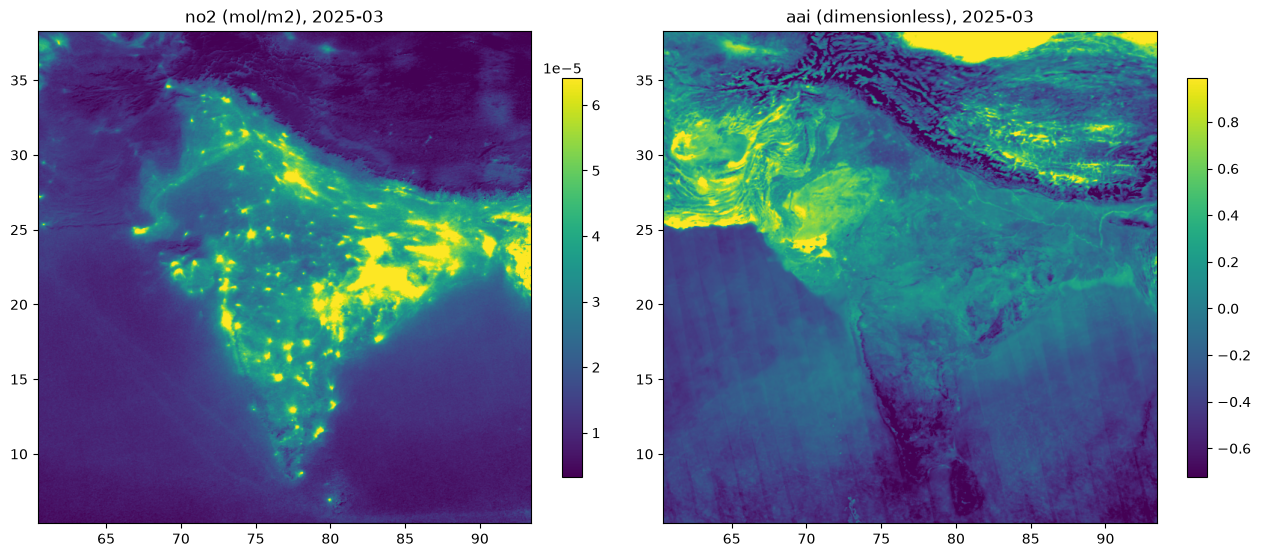

In [12]:
# One month on the map; change MAP_MONTH to look at another
MAP_MONTH = m_win[0][0]
extent = [grid_lons[0] - CELL_SIZE / 2, grid_lons[-1] + CELL_SIZE / 2, grid_lats[0] - CELL_SIZE / 2, grid_lats[-1] + CELL_SIZE / 2]

fig, axes = plt.subplots(1, len(IMAGE_COLLECTIONS), figsize=(13, 6))
for ax, name in zip(axes, IMAGE_COLLECTIONS):
    values = np.load(grid_path(name, MAP_MONTH))[0]  # row 0 is the northernmost row, which imshow draws at the top
    low, high = np.nanquantile(values, [0.02, 0.98])
    image = ax.imshow(values, extent=extent, vmin=low, vmax=high, cmap="viridis")
    ax.set_title(f"{name} ({sat_config['units'][name]}), {MAP_MONTH:%Y-%m}")
    fig.colorbar(image, ax=ax, shrink=0.7)
fig.tight_layout()
fig.savefig(MAPS_DIR / f"grid_satellite_{MAP_MONTH:%Y-%m}.png", dpi=150)
plt.show()

Reading notes: a cell missing in every month points to a permanent gap (for example no overpass over a mountain edge), a month with a much larger share is a data-coverage problem like July 2025 at the stations. The colour scale of the maps is clipped to the 2nd-98th percentile so a few extreme cells do not wash out the pattern. The station-versus-cell comparison is not expected to be exact: a buffer of 2 km radius and a cell of 0.05 degrees cover different areas. What matters for the model is that the ranking agrees (Spearman) and that the two are on the same scale.

## Step 6 - Assemble the grid feature table for Phase L

One row per cell and month, with the columns of the definitive model. The ERA5 values come from notebook 05, joined on `cell_id` and month; the month encoding is the one notebook 09 used for the training table. The population layers do not enter the model, but Phase N needs them, so they ride along.

In [14]:
with open("../configs/model_training_metadata.yaml") as f:
    model_features = yaml.safe_load(f)["definitive_model"]["features"]

# Meteorology: only the variables the model uses
meteo = xr.open_dataset(Path(gen_config["data_dir"]["clean"]) / "meteorology" / "gridded_meteo.nc")
meteo_vars = [feature for feature in model_features if feature in meteo.data_vars]
meteo_df = meteo[meteo_vars].reset_coords(drop=True).to_dataframe().reset_index()
meteo_df["month"] = meteo_df["month"].dt.to_period("M")
meteo_df[meteo_vars] = meteo_df[meteo_vars].astype("float32")

master_grid_df = grid_satellite_df.merge(meteo_df, on=["cell_id", "month"], how="left", validate="one_to_one")
del meteo_df

# Cyclic month encoding, as in notebook 09
master_grid_df["month_of_year"] = master_grid_df["month"].dt.month
master_grid_df["sin_month"] = np.sin(2 * np.pi * master_grid_df["month_of_year"] / 12).astype("float32")
master_grid_df["cos_month"] = np.cos(2 * np.pi * master_grid_df["month_of_year"] / 12).astype("float32")

# Static layers (not model features), one row per cell
static_layers = pd.read_parquet(Path(gen_config["data_dir"]["clean"]) / "population" / "grid_features.parquet")
master_grid_df = master_grid_df.merge(static_layers, on="cell_id", how="left", validate="many_to_one")

absent = [feature for feature in model_features if feature not in master_grid_df.columns]
assert not absent, f"Model features missing from the grid table: {absent}"

complete = master_grid_df[model_features].notna().all(axis=1)
print(f"{len(master_grid_df):,} rows, {complete.sum():,} ({complete.mean():.2%}) with every model feature present")
master_grid_df[model_features].isna().mean().rename("share_missing").to_frame().style.format("{:.2%}")

6,959,040 rows, 6,959,040 (100.00%) with every model feature present


,share_missing
no2,0.00%
aai,0.00%
total_precipitation,0.00%
temperature,0.00%
dew_point,0.00%
u_wind,0.00%
v_wind,0.00%
wind_magnitude,0.00%
boundary_layer_height,0.00%
surface_pressure,0.00%


In [15]:
# Where the incomplete rows are: by month
incomplete_by_month = (~complete).groupby(master_grid_df["month"]).mean().rename("share_incomplete")
incomplete_by_month.to_frame().style.format("{:.2%}")

,share_incomplete
month,
2025-03,0.00%
2025-04,0.00%
2025-05,0.00%
2025-06,0.00%
2025-07,0.00%
2025-08,0.00%
2025-09,0.00%
2025-10,0.00%
2025-11,0.00%


Reading notes: Phase L can only predict the rows with every feature present; the table shows which feature and which months cost rows. The meteorology covers the same 16 months as the satellite windows, so a missing ERA5 value means the cell lies outside the ERA5 interpolation, not a missing month.

## Step 7 - Save

In [16]:
SATELLITE_PATH = CLEAN_DATA_DIR / "grid_satellite.parquet"
MASTER_GRID_PATH = PROCESSED_DATA_DIR / "master_grid_df.parquet"

grid_satellite_df.to_parquet(SATELLITE_PATH)
master_grid_df.to_parquet(MASTER_GRID_PATH)

metadata = {
    "route": "fetch_earthengine.download_image_on_grid, monthly mean composite with the source projection restored (setDefaultProjection), mean and standard deviation of the source pixels in each cell",
    "source_pixel_scale_m": int(REDUCER_SCALE),
    "grid_cell_size_deg": float(CELL_SIZE),
    "image_collections": {name: ":".join(spec) for name, spec in IMAGE_COLLECTIONS.items()},
    "months": [start.strftime("%Y-%m") for start, _ in m_win],
    "n_cells": int(len(analysis_grid)),
    "n_rows": int(len(master_grid_df)),
    "share_missing": {name: float(grid_satellite_df[name].isna().mean()) for name in IMAGE_COLLECTIONS},
    "model_features": list(model_features),
    "model_features_share_missing": {feature: float(master_grid_df[feature].isna().mean()) for feature in model_features},
    "rows_complete_for_model": int(complete.sum()),
    "files": {"grid_satellite": str(SATELLITE_PATH), "master_grid": str(MASTER_GRID_PATH), "raw_arrays": str(RAW_DATA_DIR)},
    "library_versions": {"earthengine-api": ee.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
with open("../configs/grid_satellite_metadata.yaml", "w") as f:
    yaml.safe_dump(metadata, f, sort_keys=False)